In [2]:
import numpy as np
from matplotlib import colormaps
import matplotlib.pyplot as plt
from typing import Optional

from sklearn.neighbors import NearestNeighbors

from  sklearn.manifold import TSNE

from matplotlib.lines import Line2D

from pathlib import Path

In [3]:
ROOT_FOLDER = Path().cwd().parent
PLOT_FOLDER = ROOT_FOLDER / "results" / "plots"
PLOT_FOLDER.mkdir(parents=True, exist_ok=True)

In [4]:
def equicorr_mvn(
    n: int,
    d: int,
    rho: float,
    sigmas: Optional[np.ndarray] = None,
    mu: Optional[np.ndarray] = None,
    rng: Optional[np.random.Generator] = None
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Generates n x d matrix X.
    X ~ N_d(mu, Sigma)
    Returns a tuple (X: (n, d), mu: (d,), Sigma: (d, d))

    mu = [0, ..., 0]^T if not specified
    mu shape is (d,)
    
    Sigma is an equicorrelation matrix.
    Sigma = D @ R @ D, where D are scales and R correlations.
    R shape is (d, d), it has unit variances and correlations equal rho.
    D = diag(sigmas),
    sigmas shape is (d,), sigmas represent marginal standard deviations.
    Sigma_{ii} = [DRD]_{ii} = sigmas^2_iR_{ii} = sigmas^2_i
    """
    if d < 1:
        raise ValueError(f"d = {d} must be greater or equal 1.")
    if n < 0:
        raise ValueError(f"n = {n} must be greater or equal 0.")
        
    # Positive definite condition for Sigma
    if d > 1 and not (-1/(d-1) < rho < 1):
        raise ValueError(f"rho = {rho} is not in the positive-definite range ({-1/(d-1)}, 1).")

    # mean of the multivariate normal distribution
    mu = np.zeros(d) if mu is None else np.asarray(mu)

    if mu.shape != (d,) or not np.all(np.isfinite(mu)):
        raise ValueError(f"mu must be a finite vector of shape ({d},).")

    sigmas = np.ones(d) if sigmas is None else np.asarray(sigmas)
    
    if sigmas.shape != (d,) or not np.all(np.isfinite(sigmas)):
        raise ValueError(f"sigmas must be a finite vector of shape ({d},).")

    if np.any(sigmas <= 0):
        raise ValueError("sigmas must contain strictly positive values.")
    
    rng = np.random.default_rng() if rng is None else rng

    # covariance matrix of the multivariate normal distribution
    I_d = np.eye(d)
    R = (1 - rho) * I_d + rho * np.ones((d, d))
    
    D = np.diag(sigmas)
    Sigma = D @ R @ D
    
    X = rng.multivariate_normal(mu, Sigma, n)

    return X, mu, Sigma

In [5]:
def nancov(X: np.ndarray):
    row_nan_mask = np.isnan(X).any(axis=1)
    return np.cov(X[~row_nan_mask], rowvar=False)

In [6]:
def coord_cond_distr(
    Y: np.ndarray,
    mus: np.ndarray,
    Sigma: np.ndarray
):
    """
    Calculates the conditional distribution
    of missing coordinated given the existing coordinate values
    
    Y: m x d matrix with missingness,
        observations are in rows,
        each row has to follow the same missingness pattern
    mus: (d, ) or (d, 1) vector of means
    Sigma: (d, d) covariance matrix
    """
    if Y.size == 0:
        raise ValueError("Empty input matrix Y provided.")

    # mask checking if Y is a vector
    is_vector = Y.ndim == 1 or (Y.ndim == 2 and 1 in Y.shape)
        
    # choose missing coordinate indices
    nan_mask = np.isnan(Y)
    
    # all observations must have a consistent missingness pattern
    # if more than one observation provided
    if (
        not is_vector
        # and Y has a consistent missingness pattern across rows
        # broadcast comparison of the first row against all rows
        and not np.all(nan_mask == nan_mask[0])
    ):
        raise ValueError("Inconsistent missingness pattern in the input matrix.")

    # the mask ultimately chooses a vector coordinates,
    # it is a per observation missing mask
    if not is_vector:
        nan_mask = nan_mask[0]

    # make mask's shape consistent (d,)
    nan_mask = nan_mask.ravel()

    if not nan_mask.any():
        raise ValueError("No missing values to estimate.")

    if nan_mask.all():
        raise ValueError("No observed values to condition on.")

    mus = mus.ravel()
    # recover dimension of a observation
    d = mus.size

    if d == 1:
        raise ValueError("Conditioning existing values looses meaning for d == 1.")

    I_d = np.eye(d)
    # existing values selector matrix
    A = I_d[~nan_mask]
    # missing values selector matrix
    B = I_d[nan_mask]

    mu_A = A @ mus
    mu_B = B @ mus

    Sigma_AA = A @ Sigma @ A.T
    Sigma_AB = A @ Sigma @ B.T
    Sigma_BA = Sigma_AB.T
    Sigma_BB = B @ Sigma @ B.T
    
    K = np.linalg.solve(Sigma_AA.T, Sigma_BA.T).T

    if is_vector:
        Y_obs = Y.ravel()[~nan_mask]
    else:
        Y_obs = Y[:, ~nan_mask]

    mu_cond = mu_B + (Y_obs - mu_A) @ K.T
    Sigma_cond = Sigma_BB - K@Sigma_AB

    return mu_cond, Sigma_cond

In [7]:
def pretty_2D_scatter(ax, x, y, alpha=0.5):
    ax.scatter(
        x, y,
        s=5,
        alpha=alpha
    )

    ax.spines[['top', 'right']].set_visible(False)

    '''
    grey = '0.7'
    # Axis lines
    for spine in ax.spines.values():
        spine.set_color(grey)

    # Tick marks and tick labels
    ax.tick_params(axis="both", colors=grey)
    '''
    return ax

In [8]:
def plot_vectors(ax, vectors, colors):
    if vectors.shape[1] > len(colors):
        raise ValueError("Not enough colors to draw vectors")

    for j in range(vectors.shape[1]):
        # ax.scatter(*eigvec_Sigma_X[:, j], c="orange")
        ax.quiver(
            *mu_X,
            *vectors[:, j],
            angles="xy",
            scale_units="xy",
            scale=1,
            color=colors[j],
            width=0.003,
            headlength=7,
            headwidth=5
        )
    return ax

## Generate data

In [9]:
seed = 42
rng = np.random.default_rng(seed)

n = 1000
d = 2

rho = 0.3
sigmas = [1, 1.095]

X, mu_X, Sigma_X = equicorr_mvn(n, d, rho, sigmas=sigmas, rng=rng)
# X, mu_X, Sigma_X = equicorr_mvn(n, d, rho, rng=rng)
print(Sigma_X)

eigval_Sigma_X, eigvec_Sigma_X = np.linalg.eigh(Sigma_X)

sample_Sigma_X = nancov(X)
eigval_sample_Sigma_X, eigvec_sample_Sigma_X = np.linalg.eigh(sample_Sigma_X)

[[1.       0.3285  ]
 [0.3285   1.199025]]


In [10]:
def apply_mcar(
    X: np.ndarray,
    cols: list[int], # or other iterable?
    p: float,
    rng: Optional[np.random.Generator] = None
):
    """
    Apply MCAR missingness with probability p
    on a block of columns with indexes cols.
    """
    if max(cols) >= X.shape[1]:
        raise ValueError(f"{max(cols)} column index out of bounds.")
    # cols = np.asarray(cols)

    X_mcar = X.copy()
    
    rng = np.random.default_rng() if rng is None else rng

    missing_rows = rng.binomial(1, p, X.shape[0]).astype(bool)
    missing_rows_idx = np.flatnonzero(missing_rows)
    
    X_mcar[np.ix_(missing_rows_idx, cols)] = np.nan

    return X_mcar, missing_rows_idx

## Apply missingness

In [11]:
p = 0.3
missing_cols_idx = np.array([1])
X_mcar, missing_rows_idx = apply_mcar(X, missing_cols_idx, p, rng)
sample_p = (np.isnan(X_mcar).sum(axis=0) / X.shape[0])[missing_cols_idx]
# check missingness
assert np.allclose(sample_p, p, atol=1e-1)

## Impute

### Unconditional mean

In [12]:
X_imp_umean = X_mcar.copy()
X_mcar_sample_mus = np.nanmean(X_mcar, axis=0)
missing_grid = np.ix_(missing_rows_idx, missing_cols_idx)
X_imp_umean[missing_grid] = X_mcar_sample_mus[missing_cols_idx]

### Conditional mean

In [13]:
X_mcar_sample_cov = nancov(X_mcar)
imp_cond_means, imp_cond_Sigma = coord_cond_distr(X_mcar[missing_rows_idx], X_mcar_sample_mus, X_mcar_sample_cov)
X_imp_cmean = X_mcar.copy()
X_imp_cmean[missing_grid] = imp_cond_means

### Stochastic imputation

In [14]:
res_mus = np.zeros(missing_cols_idx.size)
X_imp_stoch = X_mcar.copy()
X_imp_stoch[missing_grid] = imp_cond_means + rng.multivariate_normal(res_mus, imp_cond_Sigma, missing_rows_idx.size)

## Eigendecomposition analysis

In [15]:
imps = ["umean", "cmean", "stoch"]
datasets = [X_imp_umean, X_imp_cmean, X_imp_stoch]
datasets = dict(zip(imps, datasets))
sample_Sigma = {}
eigvals = {}
eigvecs = {}
for imp, ds in datasets.items():
    sample_Sigma[imp] = nancov(ds)
    eigvals[imp], eigvecs[imp] = np.linalg.eigh(sample_Sigma[imp])

A unit vectors dot product is:
$$
u^Tv = \cos(\angle(u,v))
$$
and
$$
u^Tv < 0 \Rightarrow \angle(u,v) > 90^\circ.
$$
Eigenvactors make an orthonormal basis. Flipping a sign of an eigenvector doesn't change that, the basis spans the same space and defines the same PCA axis.
$$(-u)^Tv = -u^Tv = 0$$
so the vectors stay perpendicular and are still of length 1.

Those properties are used to align eigenvectors so they point in similar direction along an axis.

In [16]:
def align_vector_directions(us, vs):
    """
    Aligns the direction of vs with us.
    It is assumed vectors are in columns
    """
    dot_prods = np.sum(us * vs, axis=0)
    signs = np.where(dot_prods > 0, 1, -1)

    return vs * signs

In [17]:
eigvec_sample_Sigma_X = align_vector_directions(eigvec_Sigma_X, eigvec_sample_Sigma_X)
for imp, _ in datasets.items():
    eigvecs[imp] = align_vector_directions(eigvec_Sigma_X, eigvecs[imp])

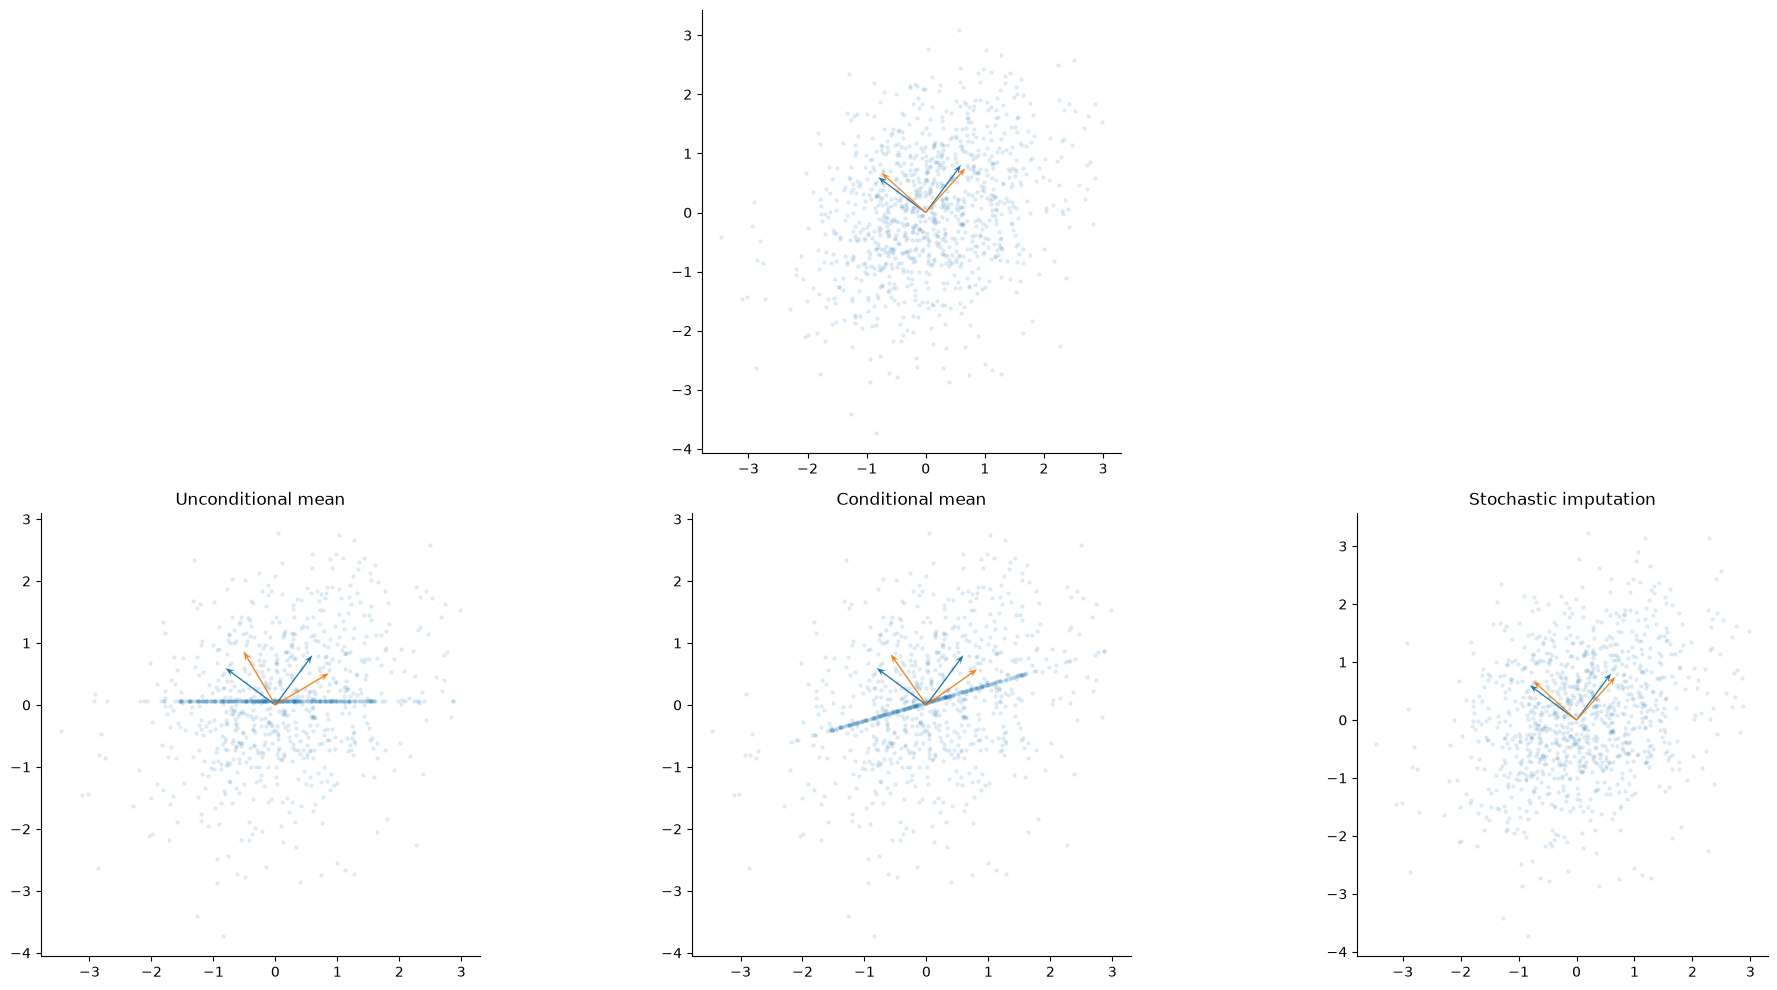

In [18]:
fig, axs = plt.subplots(2, 3, figsize=(20,10))
axs[0,0].set_visible(False)
axs[0,2].set_visible(False)

# TODO set limits so vectors are not cropped

### truth against sample eigenvectors ###
pretty_2D_scatter(axs[0,1], X[:,0], X[:,1], alpha=0.1)

vectors = np.hstack((eigvec_Sigma_X, eigvec_sample_Sigma_X))
colors = [colormaps["tab10"](c) for c in range(vectors.shape[1] // 2) for _ in range(2)]
plot_vectors(axs[0,1], vectors, colors)

### truth against eigenvectors from imputed ###
imp_names = [
    "Unconditional mean",
    "Conditional mean",
    "Stochastic imputation"
]
titles = dict(zip(imps, imp_names))
for i, (imp, ds) in enumerate(datasets.items()):
    pretty_2D_scatter(axs[1,i], ds[:,0], ds[:,1], alpha=0.1)

    vectors = np.hstack((eigvec_Sigma_X, eigvecs[imp]))
    plot_vectors(axs[1,i], vectors, colors)
    axs[1,i].set_title(titles[imp])

for ax in axs.flatten():
    ax.set_aspect("equal", adjustable="box")

fig.tight_layout()
plt.show()

## Neighbourhood analysis

### Neighbourhood stability

In [19]:
def perc_of_repeated_neighbors(NN_x, NN_y):
    """
    Each row or NN_x and NN_y holds indices of nearest neighbors for each row.
    It is assumed NN_x and NN_y have the same no of rows
    and each row in each array corresponds to the same data point.
    
    The function for each row calculates the amount of nearest neighbors from NN_x
    which are in the NN_y.
    """
    # broadcast each transposed row of NN_x along each row of NN_y
    # True in a column means index from NN_x row is in the corresponding NN_y row
    if NN_x.shape[0] != NN_y.shape[0]:
        raise ValueError("Input arrays have to have equal number of rows.")
        
    exist = NN_x[:, :, None] == NN_y[:, None, :]
    counts = exist.any(axis=-1).sum(axis=-1)
    percs = 100 * counts / NN_x.shape[1]

    return percs

In [20]:
existing_rows = np.arange(X.shape[0])
existing_rows_idx = np.flatnonzero(~np.isin(existing_rows, missing_rows_idx))

In [21]:
perplexity = np.arange(10, 60, 10)
perplexity = 3 * perplexity + 1
ks = np.hstack((np.arange(5, 25, 5), perplexity))
perc_shared_rows = {}
perc_shared_rows_miss = {}
perc_shared_rows_exist = {}
for k in ks:
    X_NN = NearestNeighbors(n_neighbors=k + 1).fit(X).kneighbors(X, return_distance=False)
    NN = {}
    for imp, ds in datasets.items():
        NN[imp] = NearestNeighbors(n_neighbors=k + 1).fit(ds).kneighbors(ds, return_distance=False)
    for imp, nn in NN.items():
        rep_neigh = perc_of_repeated_neighbors(X_NN[:, 1:], nn[:, 1:])
        perc_shared_rows[imp, k] = rep_neigh.mean()
        perc_shared_rows_miss[imp, k] = rep_neigh[missing_rows_idx].mean()
        perc_shared_rows_exist[imp, k] = rep_neigh[existing_rows_idx].mean()

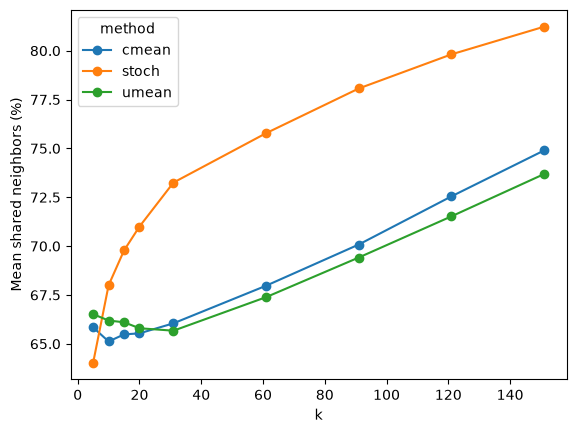

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

overlap = (
    pd.DataFrame(
        [(method, k, pct) for (method, k), pct in perc_shared_rows_exist.items()],
        columns=["method", "k", "overlap_pct"],
    )
    .pivot(index="k", columns="method", values="overlap_pct")
    .sort_index()
)

overlap.plot(marker="o", xlabel="k", ylabel="Mean shared neighbors (%)")
plt.show()

### t-SNE

In [29]:
imps = ["truth", "umean", "cmean", "stoch"]

imp_names = [
    "Complete data",
    "Unconditional mean",
    "Conditional mean",
    "Stochastic imputation"
]
titles = dict(zip(imps, imp_names))

datasets = [X, X_imp_umean, X_imp_cmean, X_imp_stoch]
datasets = dict(zip(imps, datasets))

In [30]:
perpl = 50
datasets_tsne = {}
for imp, ds in datasets.items():
    datasets_tsne[imp] = TSNE(perplexity=perpl).fit_transform(ds)

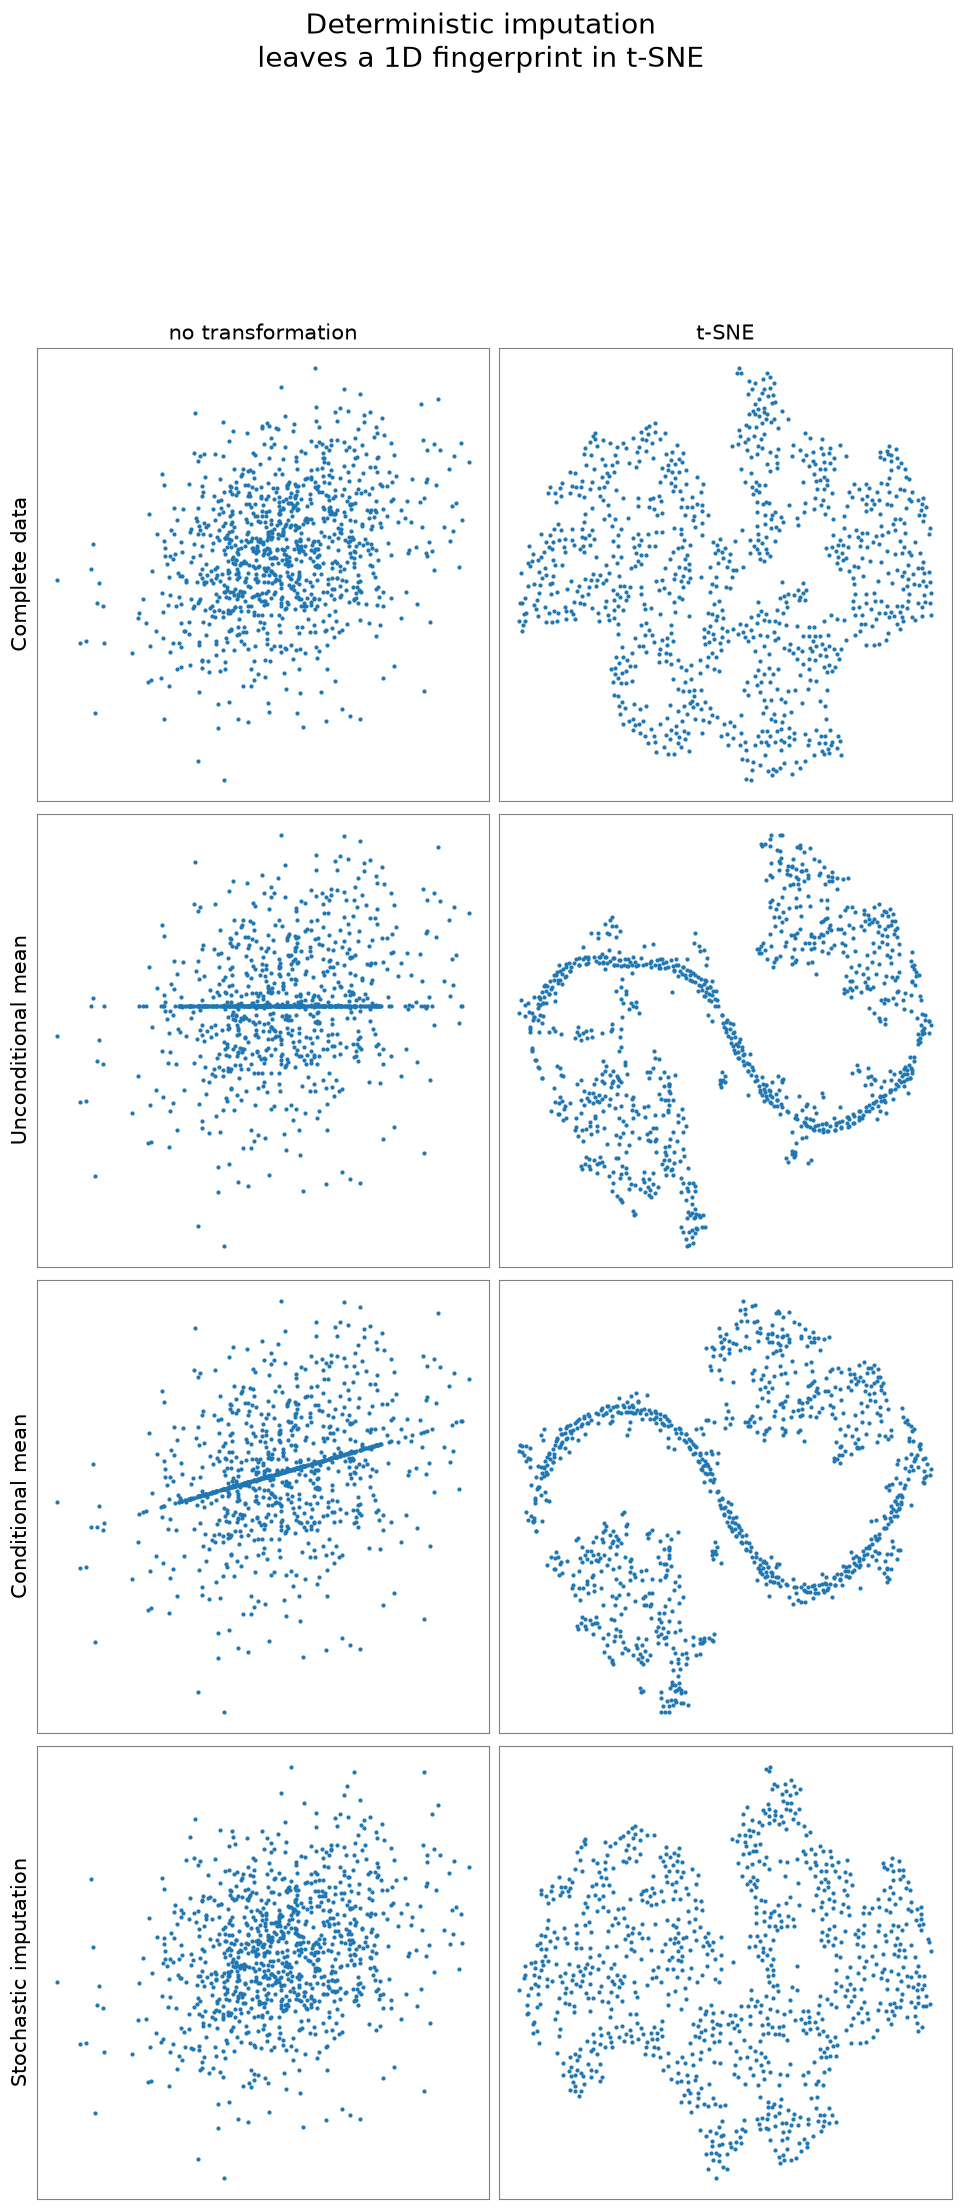

In [95]:
def plot_transformed_imputations(
    base: dict,
    transformed: dict,
    ds_names: dict,
    transform_name: str,
    fig_name: str
):
    ### input checks ###
    
    if len(base) != len(transformed) or len(base) != len(ds_names):
        raise ValueError("There has to be equal number of datasets is each dictionary.")
    if set(base.keys()) != set(transformed.keys()):
        raise ValueError(
            "Keys between input dictionaries do not match.\n"
            f"No transformation dictionary:\n{base.keys()}\n"
            f"Transformed dictionary:\n{transformed.keys()}"
        )
    if set(base.keys()) != set(ds_names.keys()):
        raise ValueError(
            "Keys between input dictionaries do not match.\n"
            f"No transformation dictionary:\n{base.keys()}\n"
            f"Dataset names dictionary:\n{ds_names.keys()}"
        )
    if None in ds_names.values():
        raise ValueError("There cannot be None in the names of the datasets.")
    if transform_name is None:
        raise ValueError("The name of transformation cannot be None.")

    ### figure and plots config ###

    RC_CONTEXT = {
        "axes.edgecolor": "grey",
        "xtick.bottom": False,
        "xtick.labelbottom": False,
        "ytick.left": False,
        "ytick.labelleft": False,
        "lines.markersize": 2,
        "figure.titlesize": 20,
        "axes.titlesize": 15,
        "axes.labelsize": 15,
        "text.latex.preamble": r"\usepackage{amsmath}",
    }

    with plt.rc_context(RC_CONTEXT):
        
        no_plot_rows = len(base)
        no_cols = 2

        info_panel_height = 2 # [inch]
        side = 4 # size of the side of the plot [inch]
        margin = 1
        
        fig_width = no_cols * side + 1.5*margin
        fig_height = (
            info_panel_height 
            + len(base) * side 
            + margin * no_plot_rows
        )
        
        fig, axs = plt.subplots(
            no_plot_rows + 1, 
            no_cols,
            figsize=(fig_width, fig_height),
            layout="constrained",
            height_ratios=[info_panel_height / side] + [1] * no_plot_rows
        )
    
        ### info panel ###
        
        axs[0, 0].set_axis_off()
        axs[0, 1].set_axis_off()
    
        ### plots ###
        axs[1, 0].set_title("no transformation")
        axs[1, 1].set_title(transform_name)
        for row, (imp, ds) in enumerate(base.items()):
            axs[row + 1, 0].set_ylabel(titles[imp])
            
            axs[row + 1, 0].scatter(*ds.T)
            axs[row + 1, 1].scatter(*transformed[imp].T)

        for ax in axs[1:].flatten():
            ax.set_box_aspect(1)

        fig.suptitle(fig_name)
        
        plt.show()

plot_transformed_imputations(
    datasets,
    datasets_tsne,
    titles,
    "t-SNE",
    "Deterministic imputation\nleaves a 1D fingerprint in t-SNE"
)

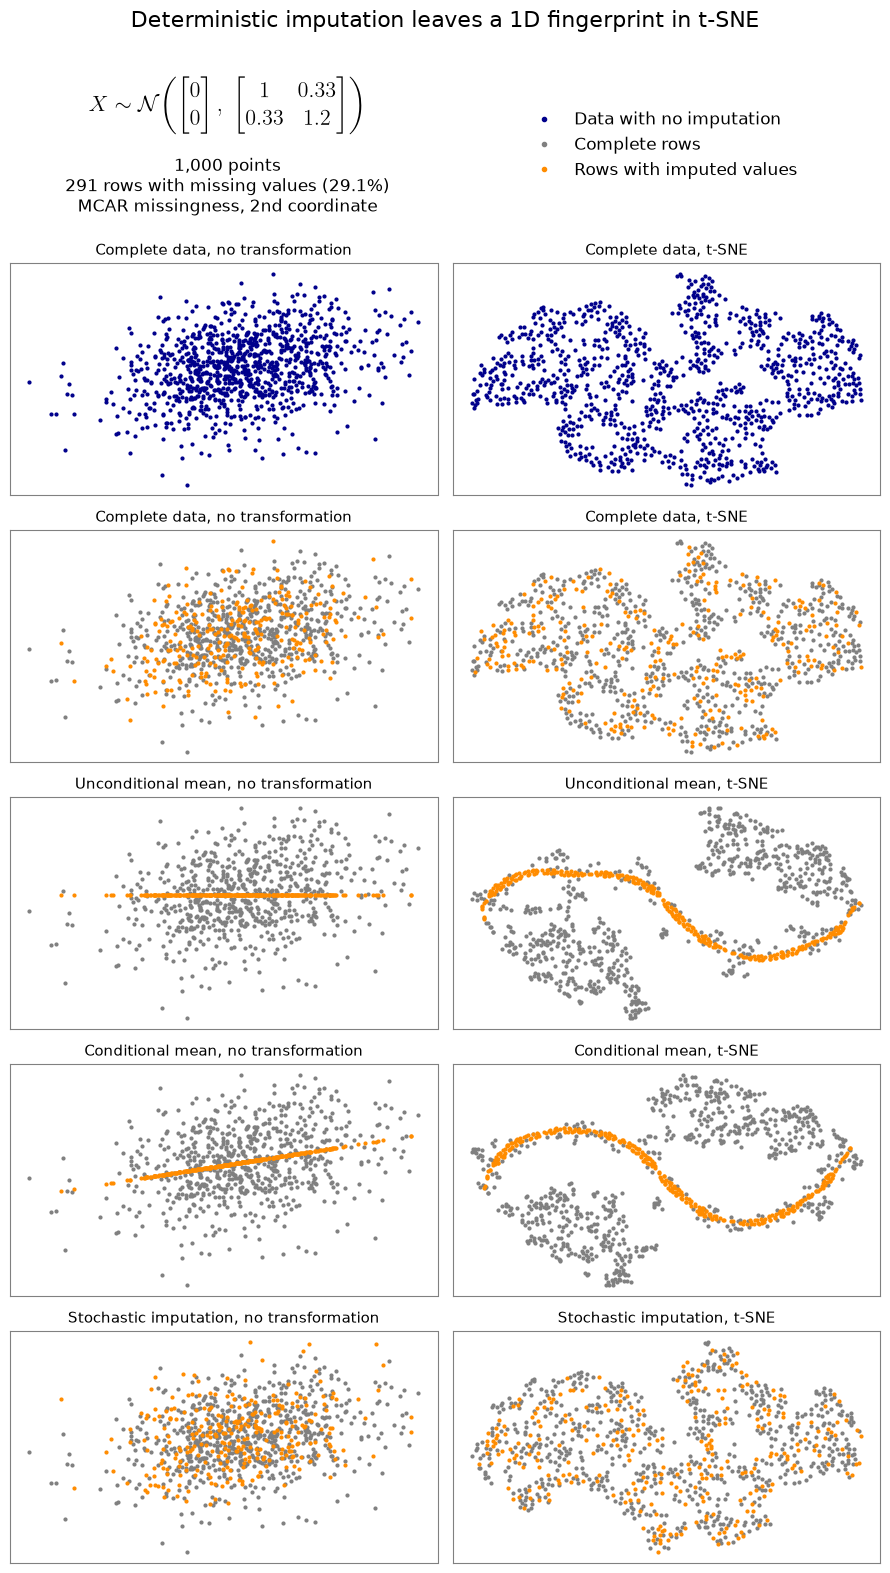

In [87]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

with plt.rc_context({
    "axes.spines.top": True,
    "axes.spines.right": True,
    "axes.spines.bottom": True,
    "axes.spines.left": True,
    "axes.edgecolor": "grey",
    "xtick.top": False,
    "xtick.bottom": False,
    "xtick.labeltop": False,
    "xtick.labelbottom": False,
    "ytick.left": False,
    "ytick.right": False,
    "ytick.labelleft": False,
    "ytick.labelright": False,
    "figure.titlesize": 16,
    "axes.titlesize": 11,
    "lines.markersize": 2,  # squared by scatter
    "text.latex.preamble": r"\usepackage{amsmath}",
}):
    n_plot_rows = 1 + len(datasets_tsne)

    # Size in inches: fixed width, fixed height per panel row.
    fig_width = 9
    panel_height = 2.8   # each scatter row
    info_height = 2.0    # top info panel
    fig = plt.figure(figsize=(fig_width, info_height + panel_height * n_plot_rows))
    grid = fig.add_gridspec(
        n_plot_rows + 1, 2,
        height_ratios=[info_height / panel_height] + [1] * n_plot_rows,
    )

    axs = {(0, 0): fig.add_subplot(grid[0, :])}
    for row in range(1, n_plot_rows + 1):
        for col in range(2):
            axs[row, col] = fig.add_subplot(grid[row, col])

    # Info panel spanning both columns
    mu_x, mu_y = mu_X
    (var_x, cov_xy), (cov_yx, var_y) = Sigma_X

    formula = (
        r"$X\sim \mathcal{N}\!\left("
        rf"\begin{{bmatrix}} {mu_x:.2g} \\ {mu_y:.2g} \end{{bmatrix}},\;"
        rf"\begin{{bmatrix}}"
        rf"{var_x:.2g} & {cov_xy:.2g} \\"
        rf"{cov_yx:.2g} & {var_y:.2g}"
        r"\end{bmatrix}\right)$"
    )

    n_points = X.shape[0]
    n_missing = X[missing_rows_idx].shape[0]

    axs[0, 0].set_axis_off()
    axs[0, 0].text(
        0.25, 0.74, formula,
        transform=axs[0, 0].transAxes,
        ha="center", va="center",
        fontsize=16,
        usetex=True,
    )
    axs[0, 0].text(
        0.25, 0.25,
        f"{n_points:,} points\n"
        f"{n_missing:,} rows with missing values ({n_missing / n_points:.1%})\n"
        "MCAR missingness, 2nd coordinate",
        transform=axs[0, 0].transAxes,
        ha="center", va="center",
        fontsize=12,
    )

    legend_handles = [
        Line2D([], [], marker="o", linestyle="none", color="darkblue",
               label="Data with no imputation"),
        Line2D([], [], marker="o", linestyle="none", color="grey",
               label="Complete rows"),
        Line2D([], [], marker="o", linestyle="none", color="darkorange",
               label="Rows with imputed values"),
    ]

    axs[0, 0].legend(
        handles=legend_handles,
        loc="center",
        bbox_to_anchor=(0.75, 0.5),
        frameon=False,
        fontsize=12,
        markerscale=1.5,
    )

    # Complete data
    axs[1, 0].scatter(*X.T, color="darkblue")
    axs[1, 0].set_title("Complete data, no transformation")

    axs[1, 1].scatter(*X_tsne.T, color="darkblue")
    axs[1, 1].set_title("Complete data, t-SNE")

    # One row per imputation method
    for row, (imp, embedding) in enumerate(datasets_tsne.items(), start=2):
        imputed_data = datasets[imp]

        axs[row, 0].scatter(*imputed_data[existing_rows_idx].T, color="grey")
        axs[row, 0].scatter(*imputed_data[missing_rows_idx].T, color="darkorange")
        axs[row, 0].set_title(titles[imp] + ", no transformation")

        axs[row, 1].scatter(*embedding[existing_rows_idx].T, color="grey")
        axs[row, 1].scatter(*embedding[missing_rows_idx].T, color="darkorange")
        axs[row, 1].set_title(titles[imp] + ", t-SNE")

    fig.suptitle("Deterministic imputation leaves a 1D fingerprint in t-SNE")
    fig.tight_layout(rect=(0, 0, 1, 0.98))

    fig.savefig(PLOT_FOLDER / "tSNE_2D_Gaussian_imputations.svg")
    fig.savefig(PLOT_FOLDER / "tSNE_2D_Gaussian_imputations.png", dpi=300)

    plt.show()

### UMAP

In [89]:
from umap import UMAP
transformer = UMAP(
    compatibility_layout=True,
    init="spectral",
    optimizer="compatibility",
    n_jobs=1,
    random_state=42,
)
datasets_umap = {}
for imp, ds in datasets.items():
    datasets_umap[imp] = transformer.fit_transform(ds)

/usr/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


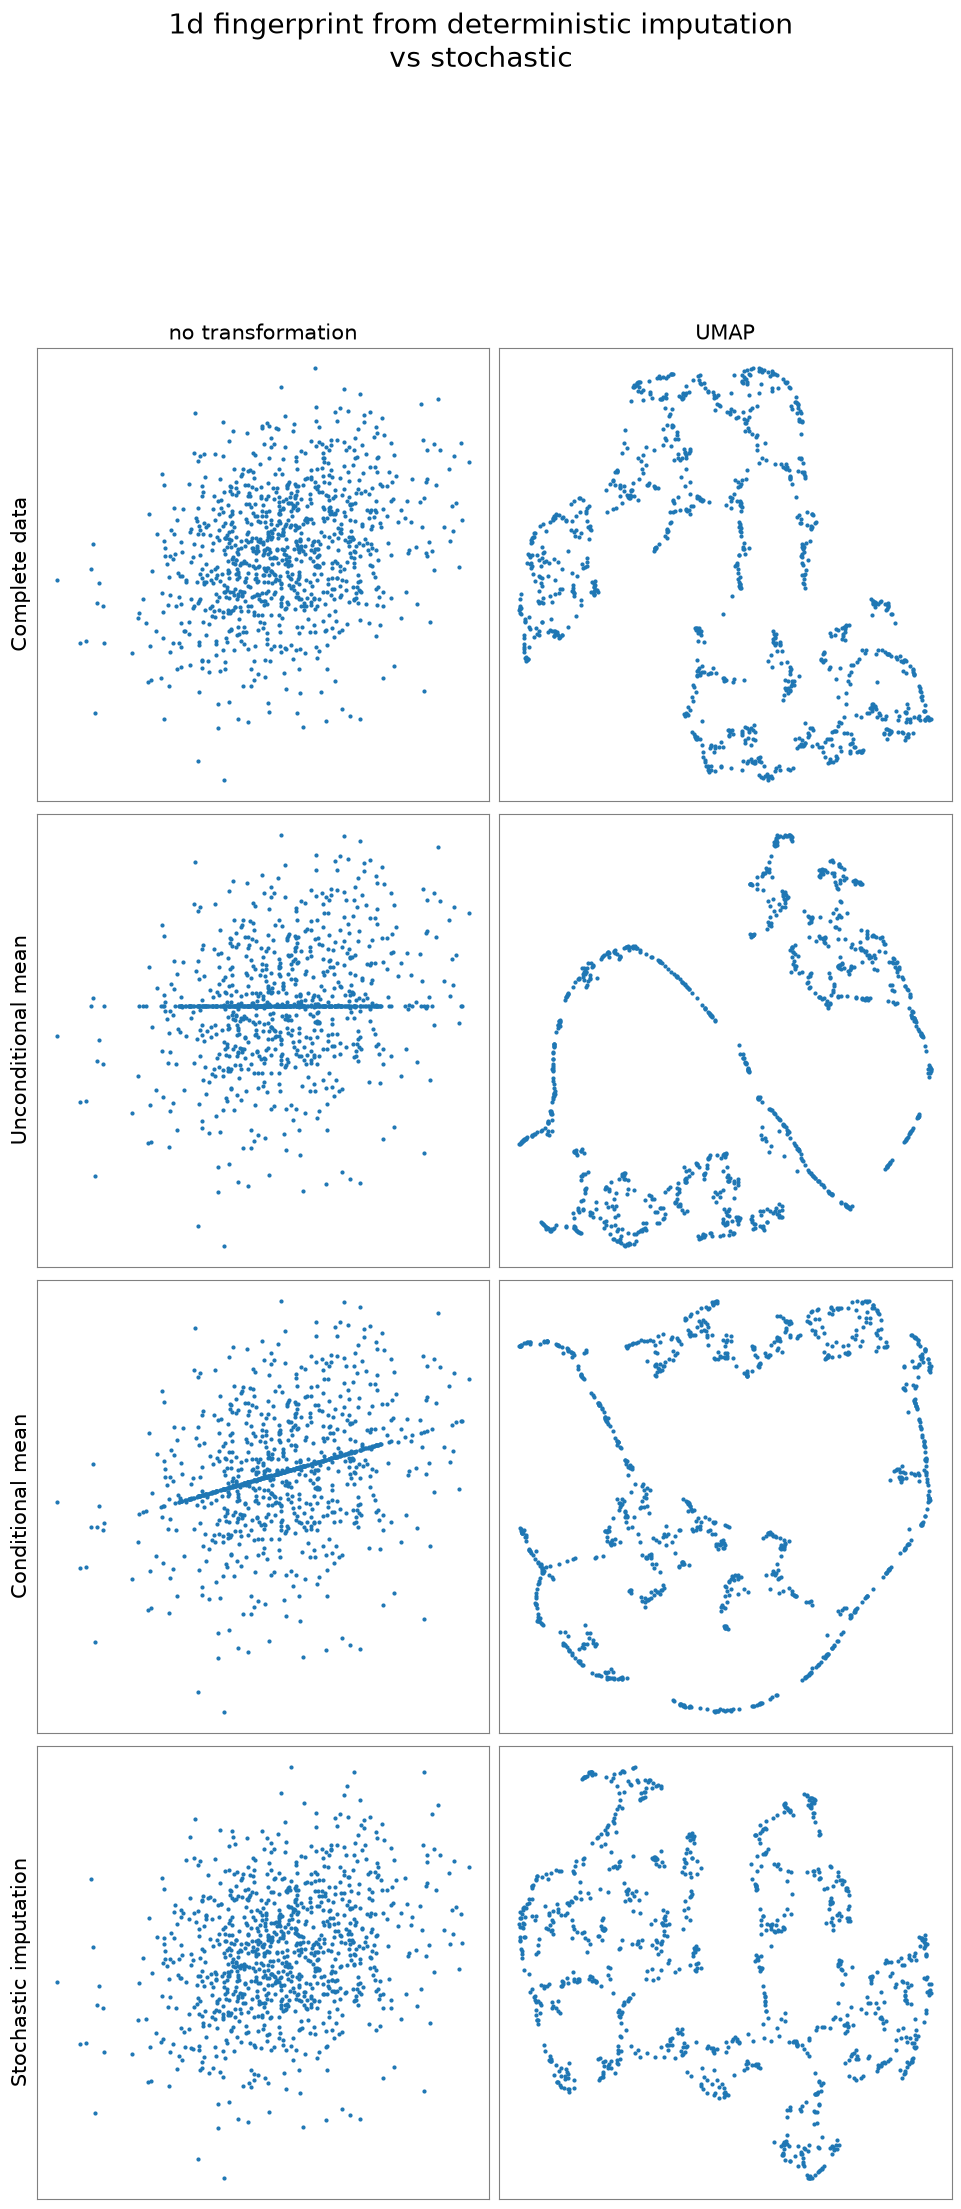

In [96]:
plot_transformed_imputations(
    datasets,
    datasets_umap,
    titles,
    "UMAP",
    "1d fingerprint from deterministic imputation\nvs stochastic"
)